# Materi 7: Text Tructure Mining 

komputer dengan komputer itu bisa menggunakan graph, jadi ketika kita membentuk struktur data yang seperti itu, maka analysis kita daalah analysis graph, 

apa itu graph, graph adalah kumpuan simpul atau vertex, yang dihubungkan oleh sisi atau edge, contoh : hubungan pertemanan di dalam media sosial
maka di dalam jaringan nanti akan muncul jaringan yang kompleks, maka kita butuh analysis graph, dikenal dengan sosial epoch analisys , kalau hubungan kata dengan kata dimana titik adalah kata atau smpulnya kata, dan kemudian saya ambil 2 kata, maka sebuah graph itu akan terhubungan, 

setelah kalian menyambungkan semua kata maka akan membentuk keyword, kalau kita membangun sebuah graph adalah hubungan kata dengan kata di sebuah dokumen, maka kita akan menghasilkan keyword, kalau kita menghubungkan kalimat dengan kalimat dalam sebuah graph, maka kalian akan mendapatkan ringkasan, kalau kalian bisa menyatakan hubungan web dengan web, kalian akan mendapatkan web penting, itu tergantung kepada bagaimana object itu dinyatakan dalam sebuah graph, kalo keterkaitan antar kata tbergantung kepada cara kita membangun strukturnya, ketika saya mengambil windows, atau saya mengatakan di geser geser, maka akan membuat suatu hubungan. 


nanti hubungan itu bisa di kasih bobot, misal kota dengan kota maka bobotnya adalah jarak, maka nanti ada graph berbobot, nanti kalau grapg berbobot jadi sisinya nanti punya nilai

V itu past iada simpul, jadi kalau gaada simpul maka tidak akan membentuk graph, adanya himpunan simpul, dua simpul a dan b disebut bertetangga jika (a.b) e E, kalo yang a , b tidak sama dengan b , a, karena tidak sama dengan arah, contoh : Follow dan follower, a follow b, tetapi b tidak follow a, jadi ada diagram berarah dan tidak berarah, 

komputer itu tau nya matriks, jadi yang kita bangun adalah dalam bentuk matriks, maka kalau saya nyatakan hubungan graph dengan matriks, maka ada keterkaitan, atau sisi, 

derajat, 

derajat masuk berarti berapa sisi yang masuk, dan derajat keluar berapa sisi yang keluar, kalau seperti ini, kalau panah yang masuk 1, berarti in bb nya 1, kemudian disribusi drajat, nant ibisa dinyatakan dalam bentuk diagram batahng, 

power-law distribution, distribusi drajat pada jaringan skala besar seringkali mengikuti 

derajar rata rata, jadi setiap note itu pnya derajar yang dianyatakan dengan Ki, 1 per N nanti ada 

buatkan graph yang nilai clusternya = 1


## Graph 5 vertex: yang tidak berarah dulu

Kita bikin graphnya pakai networkx. 5 vertex, labelnya A sampai E, edgenya kutentuin sendiri


vertex : ['A', 'B', 'C', 'D', 'E']
edges  : [('A', 'B'), ('A', 'C'), ('B', 'C'), ('C', 'D'), ('D', 'E')]

vertex A -> degree 2
vertex B -> degree 2
vertex C -> degree 3
vertex D -> degree 2
vertex E -> degree 1
total degree = 10 | jumlah edge = 5


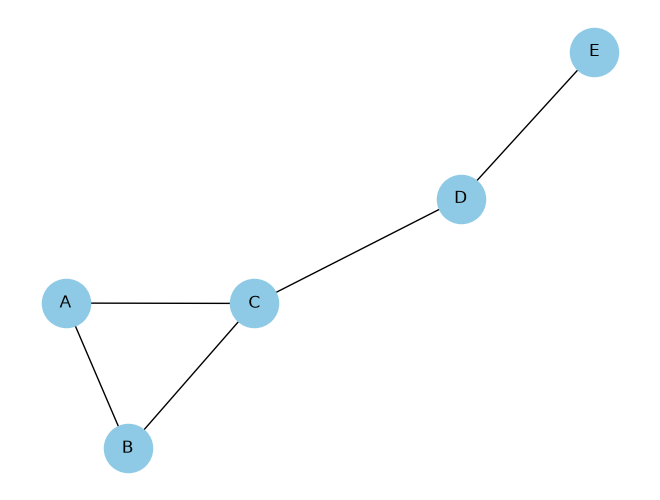

In [1]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()                                  # tidak berarah
G.add_edges_from([("A", "B"), ("A", "C"), ("B", "C"),
                  ("C", "D"), ("D", "E")])

print("vertex :", sorted(G.nodes))
print("edges  :", sorted(G.edges))
print()
for v in sorted(G.nodes):
    print("vertex", v, "-> degree", G.degree(v))
print("total degree =", sum(dict(G.degree).values()),
      "| jumlah edge =", G.number_of_edges())

nx.draw(G, with_labels=True, node_color="#8ecae6", node_size=1200)
plt.show()


### penjelasan

Pas kujalankan, hasilnya: vertex [A, B, C, D, E], edges [(A,B), (A,C), (B,C), (C,D), (D,E)]. Degree per vertex: A=2, B=2, C=3, D=2, E=1.

Cek manual biar gak cuma percaya: C itu bersambung ke A (edge A-C), ke B (edge B-C), dan ke D (edge C-D). Tiga edge nempel di dia, jadi degree C = 3. E cuma ketemu D doang, jadi degree E = 1

## Trus yang berarah

Di catetanku ada contoh follow dan follower kan? Ini dia versi komputernya. A nyambung ke B secara berarah itu beda sama B nyambung ke A, karna panahnya cuma boleh jalan satu arah.


vertex : ['A', 'B', 'C', 'D', 'E']
edges  : [('A', 'B'), ('B', 'C'), ('C', 'A'), ('C', 'D'), ('D', 'E'), ('E', 'C')]

vertex A -> in 1 | out 1 | total 2
vertex B -> in 1 | out 1 | total 2
vertex C -> in 2 | out 2 | total 4
vertex D -> in 1 | out 1 | total 2
vertex E -> in 1 | out 1 | total 2
jumlah edge = 6


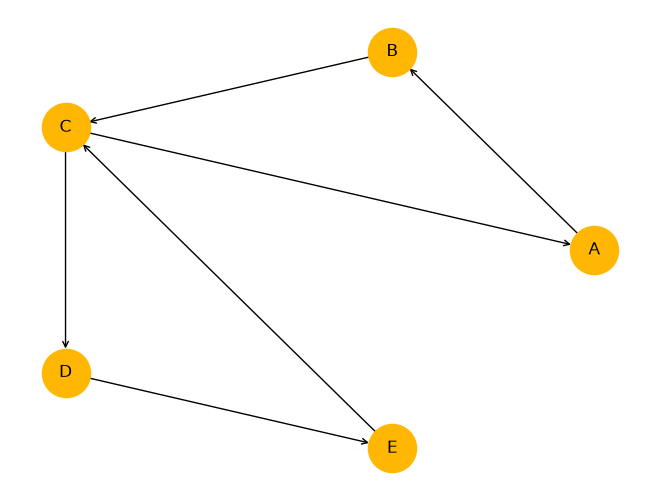

In [2]:
import networkx as nx
import matplotlib.pyplot as plt

D = nx.DiGraph()                                # berarah
D.add_edges_from([("A", "B"), ("B", "C"), ("C", "A"),
                  ("C", "D"), ("D", "E"), ("E", "C")])

print("vertex :", sorted(D.nodes))
print("edges  :", sorted(D.edges))
print()
for v in sorted(D.nodes):
    print("vertex", v, "-> in", D.in_degree(v),
          "| out", D.out_degree(v), "| total", D.degree(v))
print("jumlah edge =", D.number_of_edges())

pos = nx.circular_layout(D)
nx.draw(D, pos, with_labels=True, node_color="#ffb703",
        node_size=1200, arrows=True, arrowstyle="->")
plt.show()


### penjelasan 

Hasilnya gini: A in 1 out 1, B in 1 out 1, C in 2 out 2 (total 4), D in 1 out 1, E in 1 out 1. Jumlah edge = 6.

Cek manual buat C. Panah masuk ke C ada dua: dari B (B ke C) dan dari E (E ke C). Panah keluar dari C jugak dua: ke A (C ke A) dan ke D (C ke D). Jadi in 2, out 2, total 4. Cocok.

Total semua out = 1+1+2+1+1 = 6, dan total semua in jugak 6. Itu bukan kebetulan: tiap edge pasti mulai dari satu vertex dan berhenti di satu vertex lain, jadi jumlah panah keluar selalu sama dengan jumlah panah masuk.


## dari catetanku sendiri: graph yang nilai clustering-nya 1

Di bagian bawah catetan kamu nulis "buatkan graph yang nilai clusternya = 1". Cara paling gampang: graph lengkap alias complete graph, di mana semua vertex nyambung ke semua vertex lain. Di sana, vertex mana pun yang kamu pilih, tetangga-tetangganya pasti saling nyambung jugak, jadi clustering-nya 1 semua.


In [3]:
import networkx as nx

K = nx.complete_graph(5)                        # K5, semua nyambung semua
print("vertex :", list(K.nodes))
print("edges :", K.number_of_edges())
print("degree tiap vertex:", dict(K.degree))
print("average clustering =", nx.average_clustering(K))


vertex : [0, 1, 2, 3, 4]
edges : 10
degree tiap vertex: {0: 4, 1: 4, 2: 4, 3: 4, 4: 4}
average clustering = 1.0


### penjelasan 

Outputnya gini: vertex ada 5, edges ada 10, degree tiap vertex semuanya 4, dan average clustering = 1.0.

Kenapa bisa gini? Ingat definisi clustering coefficient: fraksi pasangan tetangga satu vertex yang antar mereka juga nyambung. Di K5 semua vertex nyambung ke semua vertex lain, jadi pasangan tetangga siapa pun pasti nyambung. Tiap vertex clustering-nya 1, rata-ratanya 1 jugak.

Degree 4 itu jugak konsisten: 5 vertex kali degree 4 = 20, dibagi 2 karena setiap edge kehitung dari dua sisi = 10 edge. Total degree = dua kali jumlah edge lagi kan, sama kayak teori di bagian tidak berarah tadi.


## Lanjutan hitung-hitungan buat kedua graph


In [4]:
import networkx as nx
import pandas as pd

G = nx.Graph()                                  # graph yang tidak berarah
G.add_edges_from([("A", "B"), ("A", "C"), ("B", "C"),
                  ("C", "D"), ("D", "E")])

print("degree tiap vertex :", dict(G.degree()))
print("rata2 degree       :",
      sum(dict(G.degree).values()) / G.number_of_nodes())
print("rata2 lintasan terpendek:", nx.average_shortest_path_length(G))
print()
cl = nx.clustering(G)
print("klasterisasi tiap vertex:")
for v in sorted(cl):
    print("  vertex", v, "=", cl[v])
print("rata2 klasterisasi :", nx.average_clustering(G))
print()
dist = {}
for d in dict(G.degree()).values():
    dist[d] = dist.get(d, 0) + 1
print("distribusi degree (degree: banyak vertex):",
      dict(sorted(dist.items())))
print("density graph      :", nx.density(G))
print()
print("matriks adjacency:")
print(pd.DataFrame(nx.to_numpy_array(G, nodelist=list("ABCDE")),
                   index=list("ABCDE"), columns=list("ABCDE")))


degree tiap vertex : {'A': 2, 'B': 2, 'C': 3, 'D': 2, 'E': 1}
rata2 degree       : 2.0
rata2 lintasan terpendek: 1.7

klasterisasi tiap vertex:
  vertex A = 1.0
  vertex B = 1.0
  vertex C = 0.3333333333333333
  vertex D = 0
  vertex E = 0
rata2 klasterisasi : 0.4666666666666667

distribusi degree (degree: banyak vertex): {1: 1, 2: 3, 3: 1}
density graph      : 0.5

matriks adjacency:
     A    B    C    D    E
A  0.0  1.0  1.0  0.0  0.0
B  1.0  0.0  1.0  0.0  0.0
C  1.0  1.0  0.0  1.0  0.0
D  0.0  0.0  1.0  0.0  1.0
E  0.0  0.0  0.0  1.0  0.0


### penjelasan 

Yang keluar: degree A=2, B=2, C=3, D=2, E=1, terus rata2 degree = 2.0. Hitungannya gampang: total degree 10 dibagi 5 vertex, hasilnya 2.

Rata2 lintasan terpendek = 1.7. Cara hitungnya: seluruh pasangan vertex diambil (ada 10), jarak terpendek tiap pasangan dijumlah, terus dibagi banyaknya pasangan. Contohnya A ke B = 1, A ke E = 3 (lewat A-C-D-E), C ke E = 2 (lewat C-D-E). Totalnya 17, jadi 17/10 = 1.7. Artinya satu pasangan vertex rata-rata cuma butuh 1 sampai 2 langkah buat nyampan.

Klasterisasi per vertex: A = 1.0, B = 1.0, C = 0.333, D = 0.0, E = 0.0, dan rata2nya 0.467. Definisi koefisien klasterisasi: seberapa banyak tetangga-tetangga satu vertex yang antar mereka juga saling nyambung. Contoh A: tetangganya B dan C, dan B-C juga nyambung, jadi 1.0. Contoh D: tetangganya C dan E, tapi C-E gak nyambung, jadi 0.0. E cuma punya satu tetangga (D), gak ada pasangan yang bisa dites, jadi 0.0 jugak. Nilai C menarik: degree-nya paling tinggi (3) tapi klasterisasinya kecil (0.333), karna tetangganya (A, B, D) gak semua saling nyambung. Vertex paling gaul gak otomatis punya kawan-kawan yang akur.

Distribusi degree {1: 1, 2: 3, 3: 1} artinya: ada 1 vertex berdegree 1 (E), ada 3 vertex berdegree 2 (A, B, D), ada 1 vertex berdegree 3 (C). Di graph yang beneran besar sampai jutaan vertex, grafik distribusi ini biasanya turun tajam ke kanan, itu yang di catetanmu disebut power-law.

Density = 0.5. Rumusnya: jumlah edge dibagi jumlah edge maksimal yang mungkin. Graph 5 vertex yang penuh (kayak K5 di bonus tadi) punya 10 edge, graph kita cuma 5, jadi 5/10 = 0.5. Density = 1 kalo graph lengkap, terus makin mendekati 0 kalo edgenya makin jarang.

Matriks adjacency: baris A isinya 0 1 1 0 0, artinya A nyambung ke B dan C. Catat jugak: matriks graph tidak berarah pasti simetris, karna edge A-B itu nyambung dua arah, jadi nilai baris A kolom B sama aja sama baris B kolom A.


In [5]:
import networkx as nx
import pandas as pd

D = nx.DiGraph()                                # graph yang berarah
D.add_edges_from([("A", "B"), ("B", "C"), ("C", "A"),
                  ("C", "D"), ("D", "E"), ("E", "C")])

print("in degree  :", dict(D.in_degree()))
print("out degree :", dict(D.out_degree()))
print("rata2 in degree :",
      sum(dict(D.in_degree).values()) / D.number_of_nodes(),
      "| rata2 out degree :",
      sum(dict(D.out_degree).values()) / D.number_of_nodes())
print("rata2 lintasan terpendek:", nx.average_shortest_path_length(D))
print()
cl = nx.clustering(D)
print("klasterisasi tiap vertex:")
for v in sorted(cl):
    print("  vertex", v, "=", cl[v])
print("rata2 klasterisasi :", nx.average_clustering(D))
print()
dist_in, dist_out = {}, {}
for d in dict(D.in_degree()).values():
    dist_in[d] = dist_in.get(d, 0) + 1
for d in dict(D.out_degree()).values():
    dist_out[d] = dist_out.get(d, 0) + 1
print("distribusi in-degree :", dict(sorted(dist_in.items())))
print("distribusi out-degree:", dict(sorted(dist_out.items())))
print("density graph berarah:", nx.density(D))
print()
print("matriks adjacency (berarah):")
print(pd.DataFrame(nx.to_numpy_array(D, nodelist=list("ABCDE")),
                   index=list("ABCDE"), columns=list("ABCDE")))


in degree  : {'A': 1, 'B': 1, 'C': 2, 'D': 1, 'E': 1}
out degree : {'A': 1, 'B': 1, 'C': 2, 'D': 1, 'E': 1}
rata2 in degree : 1.2 | rata2 out degree : 1.2
rata2 lintasan terpendek: 2.1

klasterisasi tiap vertex:
  vertex A = 0.5
  vertex B = 0.5
  vertex C = 0.16666666666666666
  vertex D = 0.5
  vertex E = 0.5
rata2 klasterisasi : 0.4333333333333333

distribusi in-degree : {1: 4, 2: 1}
distribusi out-degree: {1: 4, 2: 1}
density graph berarah: 0.3

matriks adjacency (berarah):
     A    B    C    D    E
A  0.0  1.0  0.0  0.0  0.0
B  0.0  0.0  1.0  0.0  0.0
C  1.0  0.0  0.0  1.0  0.0
D  0.0  0.0  0.0  0.0  1.0
E  0.0  0.0  1.0  0.0  0.0


### penjelasan

Semua vertex punya in 1 out 1, kecuali C yang in 2 out 2. Rata2 in degree dan rata2 out degree sama-sama 1.2 (6 edge dibagi 5 vertex). Trus rata2 total degree = 1.2 + 1.2 = 2.4.

Rata2 lintasan terpendek = 2.1, lebih jauh dari 1.7 yang tidak berarah tadi, karna sekarang kita harus nurutin arah panah. Contohnya dari A ke E jalurnya A-B-C-D-E, 4 langkah, gak bisa ambil jalan yang arahnya kebalik.

Klasterisasi versi berarah: A = 0.5, B = 0.5, C = 0.167, D = 0.5, E = 0.5, rata2nya 0.433. Catet: rumus networkx buat graph berarah beda sama versi tidak berarah, dia ngitung triangle yang arah panahnya bener. Jadi wajar kalau angkanya gak identik sama yang tadi.

Distribusi in-degree {1: 4, 2: 1} dan out-degree {1: 4, 2: 1}: empat vertex punya degree masuk 1, satu vertex (C) punya 2, pola keluarnya sama jugak. Buat graph besar, distribusi in dan out biasanya digambar terpisah karna bentuknya bisa beda.

Density = 0.3. Di graph berarah, satu pasangan vertex boleh punya 2 panah sekaligus (A ke B dan B ke A), jadi jumlah edge maksimalnya 5 x 4 = 20, bukan 10. Graph kita punya 6 edge, jadi 6/20 = 0.3. Makanya lebih kecil dari 0.5, bukan karna edgenya makin banyak, tapi karna pembaginya jadi dobel.

Matriks adjacency berarah: baris A isinya 0 1 0 0 0, artinya cuman satu panah keluar dari A yaitu A-B. Beda dengan yang tidak berarah, matriks ini gak simetris: baris A kolom B = 1 tapi baris B kolom A = 0, karna A-B gak otomatis bikin B-A.
